# 03 — MF-BPR: Matrix Factorization with Bayesian Personalized Ranking

**Objective.** Train the first *personalized* retriever — matrix factorization
with a pairwise BPR loss, implemented from scratch in PyTorch (no RecBole/Surprise/
library training loop) — index its item embeddings with FAISS, and see whether
personalization actually beats the Popularity baseline from notebook 02.

**Why BPR, not pointwise rating prediction.** We don't care about predicting the
exact star rating a user would give a book — we care about ranking: would this
user prefer book A over book B they haven't seen? BPR directly optimizes for
that pairwise ordering (`score(user, positive) > score(user, negative)`) instead
of minimizing squared error on ratings, which is a mismatched objective for a
top-K retrieval task. This is the same reasoning the original BPR paper
(Rendle et al. 2009) makes for implicit feedback.

**Depends on notebook Data Prep's outputs**: `data/processed[_sample]/{train,val,test,items_meta}.parquet`.


## 1. Setup

In [22]:
!pip install faiss-cpu

In [23]:
import os
import sys
from pathlib import Path

DATA_ROOT = Path("/kaggle/working/data")
REPO_ROOT = Path("/kaggle/working")

PROCESSED_DIR = DATA_ROOT / "processed"
# Separate results ledger in sample mode so 500-book smoke-test numbers never
# mix with the real results table that ANALYSIS.md is built from.
INPUT_DIR = Path("/kaggle/input/notebooks/goodoldies/full-recsys-data-prep-explore/data/processed/")
RESULTS_PATH = Path("/kaggle/input/notebooks/krishanthdev/recsys-baseliners/results/metrics.csv")
BPR_RESULTS_PATH = REPO_ROOT / "results" / "metrics.csv"

In [24]:
import json
from typing import Dict, Iterable, List, Sequence, Set

import faiss
import numpy as np
import pandas as pd
import torch
import random
import torch.nn as nn
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE)

device: cpu


## 2. Helper functions

### 2.1 Evaluation harness

In [25]:
CATEGORICAL = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#898781", "ytick.color": "#898781", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=CATEGORICAL), "font.family": "sans-serif", "figure.dpi": 110,
})


def build_user_positive_sets(df, user_col="user_id", item_col="parent_asin", label_col="label") -> Dict[str, Set[str]]:
    pos = df[df[label_col] == 1]
    return pos.groupby(user_col)[item_col].apply(set).to_dict()


def build_user_history(df, user_col="user_id", item_col="parent_asin") -> Dict[str, Set[str]]:
    return df.groupby(user_col)[item_col].apply(set).to_dict()


def recall_at_k(recs, ground_truth, k) -> float:
    scores = []
    for u, gt in ground_truth.items():
        if not gt:
            continue
        hits = len(set(recs.get(u, [])[:k]) & gt)
        scores.append(hits / len(gt))
    return float(np.mean(scores)) if scores else 0.0


def ndcg_at_k(recs, ground_truth, k) -> float:
    scores = []
    for u, gt in ground_truth.items():
        if not gt:
            continue
        topk = recs.get(u, [])[:k]
        dcg = sum(1.0 / np.log2(i + 2) for i, it in enumerate(topk) if it in gt)
        idcg = sum(1.0 / np.log2(i + 2) for i in range(min(len(gt), k)))
        scores.append(dcg / idcg if idcg > 0 else 0.0)
    return float(np.mean(scores)) if scores else 0.0


def catalog_coverage(recs, catalog) -> float:
    catalog = set(catalog)
    if not catalog:
        return 0.0
    recommended = set()
    for items in recs.values():
        recommended.update(items)
    return len(recommended & catalog) / len(catalog)


def evaluate(recs, ground_truth, catalog, recall_ks: Sequence[int] = (20,), ndcg_ks: Sequence[int] = (10,)) -> Dict[str, float]:
    out = {}
    for k in recall_ks:
        out[f"recall@{k}"] = recall_at_k(recs, ground_truth, k)
    for k in ndcg_ks:
        out[f"ndcg@{k}"] = ndcg_at_k(recs, ground_truth, k)
    out["catalog_coverage"] = catalog_coverage(recs, catalog)
    return out


def log_result(results_path, stage, model_name, split, metrics, notes="") -> pd.DataFrame:
    results_path = Path(results_path)
    row = {"stage": stage, "model": model_name, "split": split, **metrics, "notes": notes}
    if results_path.exists():
        df = pd.read_csv(results_path)
        df = df[~((df["stage"] == stage) & (df["model"] == model_name) & (df["split"] == split))]
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    else:
        results_path.parent.mkdir(parents=True, exist_ok=True)
        df = pd.DataFrame([row])
    df.to_csv(results_path, index=False)
    return df

### 2.2 ID mapping

PyTorch embedding tables need contiguous integer indices, not raw string IDs.
We build the vocabulary from **train only** — MF-BPR has no mechanism to
represent a user/item it never saw during training (unlike the two-tower
model in notebook 04, which computes embeddings inductively from features).
This is safe because notebook 01's warm-start split guarantees every val/test
user and item already appears in train.

In [26]:
def build_id_maps(train_df, user_col="user_id", item_col="parent_asin"):
    user_ids = train_df[user_col].unique()
    item_ids = train_df[item_col].unique()
    user_to_idx = {u: i for i, u in enumerate(user_ids)}
    item_to_idx = {it: i for i, it in enumerate(item_ids)}
    idx_to_item = np.array(item_ids)
    return user_to_idx, item_to_idx, idx_to_item

### 2.3 MF-BPR model

A user's score for an item is the dot product of their embeddings plus an
item bias term (captures overall item popularity independent of any user —
without it, the model has to spend embedding capacity re-deriving "this book
is broadly liked" for every user separately). Embeddings are initialized with
small random noise so the initial pairwise scores aren't all identical (which
would give BPR a zero gradient to start from).

In [27]:
class MFBPR(nn.Module):
    def __init__(self, n_users: int, n_items: int, embedding_dim: int = 64):
        super().__init__()
        self.user_emb = nn.Embedding(n_users, embedding_dim)
        self.item_emb = nn.Embedding(n_items, embedding_dim)
        self.item_bias = nn.Embedding(n_items, 1)
        nn.init.normal_(self.user_emb.weight, std=0.01)
        nn.init.normal_(self.item_emb.weight, std=0.01)
        nn.init.zeros_(self.item_bias.weight)

    def score(self, user_idx: torch.Tensor, item_idx: torch.Tensor) -> torch.Tensor:
        u = self.user_emb(user_idx)
        i = self.item_emb(item_idx)
        b = self.item_bias(item_idx).squeeze(-1)
        return (u * i).sum(-1) + b

    def forward(self, user_idx: torch.Tensor, pos_idx: torch.Tensor, neg_idx: torch.Tensor):
        return self.score(user_idx, pos_idx), self.score(user_idx, neg_idx)


def bpr_loss(pos_score: torch.Tensor, neg_score: torch.Tensor) -> torch.Tensor:
    return -torch.log(torch.sigmoid(pos_score - neg_score) + 1e-10).mean()

### 2.4 Negative sampling & training loop

For each observed positive `(user, item)` pair, BPR needs a negative — an item
that user has *not* interacted with (any rating, not just low ones: something
they already rated 1-star is still a different training signal than something
they've never seen, so we exclude their whole history, not just their
positives). We use plain rejection sampling: draw a random item, redraw if
it's in that user's history. At this catalog size collisions are rare enough
that this stays cheap; a fully vectorized sampler would matter more at full
dataset scale (documented as a known optimization opportunity, not needed here).

In [28]:
def sample_negatives(user_idx_batch: np.ndarray, history_by_idx: Dict[int, Set[int]], n_items: int, rng: np.random.Generator) -> np.ndarray:
    neg = rng.integers(0, n_items, size=len(user_idx_batch))
    for i, u in enumerate(user_idx_batch):
        seen = history_by_idx.get(u)
        if not seen:
            continue
        while neg[i] in seen:
            neg[i] = rng.integers(0, n_items)
    return neg


def train_bpr(
    model: MFBPR, user_idx: np.ndarray, pos_idx: np.ndarray, history_by_idx: Dict[int, Set[int]],
    n_items: int, device, epochs: int = 20, batch_size: int = 1024, lr: float = 0.01,
    weight_decay: float = 1e-6, seed: int = SEED,
) -> List[float]:
    rng = np.random.default_rng(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    n = len(user_idx)
    losses = []
    model.train()
    for _ in range(epochs):
        perm = rng.permutation(n)
        epoch_loss = 0.0
        for start in range(0, n, batch_size):
            batch = perm[start:start + batch_size]
            u_batch, pos_batch = user_idx[batch], pos_idx[batch]
            neg_batch = sample_negatives(u_batch, history_by_idx, n_items, rng)

            u_t = torch.as_tensor(u_batch, dtype=torch.long, device=device)
            pos_t = torch.as_tensor(pos_batch, dtype=torch.long, device=device)
            neg_t = torch.as_tensor(neg_batch, dtype=torch.long, device=device)

            pos_score, neg_score = model(u_t, pos_t, neg_t)
            loss = bpr_loss(pos_score, neg_score)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * len(batch)
        losses.append(epoch_loss / n)
    return losses

### 2.5 FAISS retrieval

**Design decision — folding the bias into the dot product.** FAISS's
`IndexFlatIP` only computes plain inner products, but our score function is
`dot(user, item) + item_bias`. The standard trick: append the bias as an
extra embedding dimension (`item_vec' = [item_vec, item_bias]`, `user_vec' =
[user_vec, 1.0]`), so `dot(user_vec', item_vec') = dot(user_vec, item_vec) +
item_bias * 1.0` — the augmented inner product exactly reproduces the
original score, so we get correct ranking without reimplementing search.

**Design decision — Flat, not IVF.** With a catalog this size, exact search
(`IndexFlatIP`) is fast enough and gives exact top-K; `IndexIVFFlat` (approximate,
clustering-based) is the right call once the catalog reaches the 100k+ range,
which the full (non-sample) run would hit.

In [29]:
def build_faiss_index(item_emb: np.ndarray, item_bias: np.ndarray) -> faiss.Index:
    augmented = np.concatenate([item_emb, item_bias.reshape(-1, 1)], axis=1).astype("float32")
    index = faiss.IndexFlatIP(augmented.shape[1])
    index.add(augmented)
    return index


def faiss_retrieve(
    index: faiss.Index, user_emb: np.ndarray, user_ids: List[str], user_to_idx: Dict[str, int],
    idx_to_item: np.ndarray, history: Dict[str, Set[str]], k: int = 100, buffer: int = 300,
) -> Dict[str, List[str]]:
    query = np.concatenate([user_emb, np.ones((user_emb.shape[0], 1), dtype="float32")], axis=1)
    _, neighbor_idx = index.search(query, k + buffer)
    recs = {}
    for row, uid in enumerate(user_ids):
        seen = history.get(uid, set())
        candidates = [idx_to_item[j] for j in neighbor_idx[row] if j != -1 and idx_to_item[j] not in seen]
        recs[uid] = candidates[:k]
    return recs

## 3. Load the split produced by notebook 01

In [30]:
train = pd.read_parquet(INPUT_DIR / "train.parquet")
val = pd.read_parquet(INPUT_DIR / "val.parquet")
test = pd.read_parquet(INPUT_DIR / "test.parquet")

catalog = set(train["parent_asin"].unique())
train_history = build_user_history(train)
val_ground_truth = build_user_positive_sets(val)
test_ground_truth = build_user_positive_sets(test)
print(f"train={len(train):,}  val={len(val):,}  test={len(test):,}  catalog={len(catalog):,} items")

train=592,954  val=18,656  test=10,234  catalog=40,366 items


## 4. Build ID mappings and training pairs

In [31]:
user_to_idx, item_to_idx, idx_to_item = build_id_maps(train)
n_users, n_items = len(user_to_idx), len(item_to_idx)
print(f"n_users={n_users:,}  n_items={n_items:,}")

train_pos = train[train["label"] == 1]
user_idx_arr = train_pos["user_id"].map(user_to_idx).to_numpy()
pos_idx_arr = train_pos["parent_asin"].map(item_to_idx).to_numpy()
print(f"{len(user_idx_arr):,} positive training pairs")

history_by_idx = {
    user_to_idx[u]: {item_to_idx[i] for i in items if i in item_to_idx}
    for u, items in train_history.items() if u in user_to_idx
}

n_users=48,199  n_items=40,366
592,954 positive training pairs


## 5. Hyperparameter tuning (on validation, not test)

**Design decision.** We tune `embedding_dim` and learning rate on val Recall@20
with a short training budget per config, then retrain the winning config for
longer in Section 6. Tuning on test would leak information about the exact
data we're supposed to be evaluated on at the end — the whole reason notebook
01 carved out a separate val split.

In [32]:
GRID = [
    {"embedding_dim": 32, "lr": 0.01},
    {"embedding_dim": 32, "lr": 0.05},
    {"embedding_dim": 64, "lr": 0.01},
    {"embedding_dim": 64, "lr": 0.05},
]
TUNE_EPOCHS = 10

val_users = list(val_ground_truth.keys())
tuning_results = []
for cfg in GRID:
    model = MFBPR(n_users, n_items, embedding_dim=cfg["embedding_dim"]).to(DEVICE)
    train_bpr(
        model, user_idx_arr, pos_idx_arr, history_by_idx, n_items, DEVICE,
        epochs=TUNE_EPOCHS, lr=cfg["lr"], seed=SEED,
    )
    model.eval()
    with torch.no_grad():
        item_emb = model.item_emb.weight.cpu().numpy()
        item_bias = model.item_bias.weight.cpu().numpy().squeeze(-1)
        user_emb_all = model.user_emb.weight.cpu().numpy()
    index = build_faiss_index(item_emb, item_bias)
    val_user_emb = user_emb_all[[user_to_idx[u] for u in val_users]]
    val_recs = faiss_retrieve(index, val_user_emb, val_users, user_to_idx, idx_to_item, train_history, k=100)
    metrics = evaluate(val_recs, val_ground_truth, catalog, recall_ks=(20,), ndcg_ks=(10,))
    tuning_results.append({**cfg, **metrics})
    print(cfg, metrics)

tuning_df = pd.DataFrame(tuning_results).sort_values("recall@20", ascending=False)
tuning_df

{'embedding_dim': 32, 'lr': 0.01} {'recall@20': 0.03836074400594415, 'ndcg@10': 0.013107192665629345, 'catalog_coverage': 0.3119456968736065}
{'embedding_dim': 32, 'lr': 0.05} {'recall@20': 0.0174925418827657, 'ndcg@10': 0.006119269067783504, 'catalog_coverage': 0.5654758955556657}
{'embedding_dim': 64, 'lr': 0.01} {'recall@20': 0.03883731624687553, 'ndcg@10': 0.013384202905594405, 'catalog_coverage': 0.34432443145221225}
{'embedding_dim': 64, 'lr': 0.05} {'recall@20': 0.015206335128233153, 'ndcg@10': 0.004640361139173731, 'catalog_coverage': 0.6189862755784571}


,embedding_dim,lr,recall@20,ndcg@10,catalog_coverage
2,64,0.01,0.038837,0.013384,0.344324
0,32,0.01,0.038361,0.013107,0.311946
1,32,0.05,0.017493,0.006119,0.565476
3,64,0.05,0.015206,0.004640,0.618986


**Interpretation.** Pick the config with the best val Recall@20. With this small
a catalog/user base (SAMPLE_MODE), differences between configs may be small and
somewhat noisy — at full scale, expect a clearer signal and probably a wider grid.

In [33]:
best_cfg = tuning_df.iloc[0][["embedding_dim", "lr"]].to_dict()
best_cfg["embedding_dim"] = int(best_cfg["embedding_dim"])
print("Best config:", best_cfg)

Best config: {'embedding_dim': 64, 'lr': 0.01}


## 6. Final training with the best config

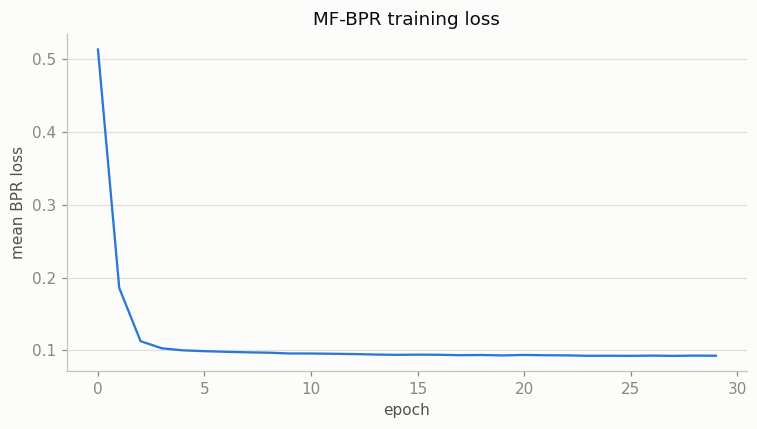

In [34]:
FINAL_EPOCHS = 30

model = MFBPR(n_users, n_items, embedding_dim=best_cfg["embedding_dim"]).to(DEVICE)
losses = train_bpr(
    model, user_idx_arr, pos_idx_arr, history_by_idx, n_items, DEVICE,
    epochs=FINAL_EPOCHS, lr=best_cfg["lr"], seed=SEED,
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(losses, color=CATEGORICAL[0])
ax.set_xlabel("epoch")
ax.set_ylabel("mean BPR loss")
ax.set_title("MF-BPR training loss")
plt.tight_layout()
plt.show()

**Interpretation.** Loss should drop steadily and flatten out — a still-falling
curve at the last epoch means more epochs would likely help; a flat curve from
epoch 1 suggests the learning rate is too low or too high (check both ends of
the grid above).

## 7. Index with FAISS and retrieve top-100

In [35]:
model.eval()
with torch.no_grad():
    item_emb = model.item_emb.weight.cpu().numpy()
    item_bias = model.item_bias.weight.cpu().numpy().squeeze(-1)
    user_emb_all = model.user_emb.weight.cpu().numpy()

index = build_faiss_index(item_emb, item_bias)

val_users = list(val_ground_truth.keys())
test_users = list(test_ground_truth.keys())
val_user_emb = user_emb_all[[user_to_idx[u] for u in val_users]]
test_user_emb = user_emb_all[[user_to_idx[u] for u in test_users]]

val_recs = faiss_retrieve(index, val_user_emb, val_users, user_to_idx, idx_to_item, train_history, k=100)
test_recs = faiss_retrieve(index, test_user_emb, test_users, user_to_idx, idx_to_item, train_history, k=100)

## 8. Evaluate

In [36]:
val_metrics = evaluate(val_recs, val_ground_truth, catalog, recall_ks=(20, 50), ndcg_ks=(10,))
test_metrics = evaluate(test_recs, test_ground_truth, catalog, recall_ks=(20, 50), ndcg_ks=(10,))
print("MF-BPR | val: ", val_metrics)
print("MF-BPR | test:", test_metrics)

log_result(BPR_RESULTS_PATH, "retrieval", "MF-BPR", "val", val_metrics)
log_result(BPR_RESULTS_PATH, "retrieval", "MF-BPR", "test", test_metrics)
print("Logged to", BPR_RESULTS_PATH)

MF-BPR | val:  {'recall@20': 0.0415176008670674, 'recall@50': 0.08031049916690906, 'ndcg@10': 0.012886547841217571, 'catalog_coverage': 0.3549026408363474}
MF-BPR | test: {'recall@20': 0.03795197778633854, 'recall@50': 0.07917885130881085, 'ndcg@10': 0.010996598767184628, 'catalog_coverage': 0.3103106574840212}
Logged to /kaggle/working/results/metrics.csv


## 9. Compare against the baselines

In [37]:
import pandas as pd

dfs = []

if RESULTS_PATH.exists():
    dfs.append(pd.read_csv(RESULTS_PATH))

if BPR_RESULTS_PATH.exists():
    dfs.append(pd.read_csv(BPR_RESULTS_PATH))

if dfs:
    all_results = pd.concat(dfs, ignore_index=True)

    comparison = (
        all_results[all_results["split"] == "test"]
        .set_index("model")
        [["recall@20", "recall@50", "ndcg@10", "catalog_coverage"]]
    )

    print(comparison)
else:
    print("No results found.")

            recall@20  recall@50   ndcg@10  catalog_coverage
model                                                       
Random       0.000643        NaN  0.000159          0.950949
Popularity   0.007971        NaN  0.002099          0.000793
MF-BPR       0.037952   0.079179  0.010997          0.310311


**Interpretation.** MF-BPR should beat Popularity on Recall@20/NDCG@10 (it's
now personalizing instead of showing everyone the same list) *and* on catalog
coverage (different users get different top-100 lists, instead of everyone
converging on the same handful of bestsellers). If MF-BPR does *not* clear
Popularity, that's a real signal to check before moving on — most likely causes
are too few training epochs, an embedding dimension too small for the catalog,
or a learning rate the tuning grid didn't cover well.

**Limitation to flag for ANALYSIS.md.** MF-BPR only has embeddings for users
and items seen during training — it has no way to score a brand-new user or
book without retraining. The two-tower model in notebook 04 computes user
embeddings inductively (a forward pass over user features/history), which is
what actually makes "recommend to a just-signed-up user" possible in the
webapp.

## 10. Save artifacts

Saved for reuse by the webapp (item/user embeddings + FAISS index) and by
notebook 05 (candidate generation for the LightGBM ranker).

In [38]:
CHECKPOINT_DIR = REPO_ROOT / "checkpoint"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

np.save(CHECKPOINT_DIR / "item_embeddings.npy", item_emb)
np.save(CHECKPOINT_DIR / "item_bias.npy", item_bias)
np.save(CHECKPOINT_DIR / "user_embeddings.npy", user_emb_all)
faiss.write_index(index, str(CHECKPOINT_DIR / "faiss_index.bin"))
torch.save(model.state_dict(), CHECKPOINT_DIR / "model.pt")

with open(CHECKPOINT_DIR / "id_maps.json", "w") as f:
    json.dump({
        "user_to_idx": user_to_idx,
        "item_to_idx": item_to_idx,
        "best_config": best_cfg,
    }, f)

print("Saved MF-BPR artifacts to", CHECKPOINT_DIR)

Saved MF-BPR artifacts to /kaggle/working/checkpoint


## Summary

- MF-BPR trained from scratch in PyTorch: embedding dot-product + item bias,
  pairwise BPR loss, Adam (mini-batch SGD variant) optimizer.
- Hyperparameters (`embedding_dim`, `lr`) tuned on val Recall@20, not test.
- Item embeddings indexed with FAISS (`IndexFlatIP`, bias folded in as an
  extra dimension); retrieved top-100 candidates per user.
- Reported Recall@20, Recall@50, NDCG@10, Catalog Coverage on val and test;
  logged to the shared results ledger for the final comparison table.
- Limitation: no embeddings for out-of-train users/items — motivates the
  two-tower model next.
